## BLIP-2 baseline smoke test with K = 32

Test one VQAv2 validation image/question without fine-tuning. The model is loaded through `scripts/load_blip2.ipynb`, so this notebook does not repeat the model-loading implementation.

This is a functional test (greedy decoding, one question), not the final VQAv2 accuracy benchmark. The later full evaluation will use a fixed decoding protocol across all query-count conditions.

**Note:** `%run -i` executes the loader in this notebook's kernel. If the model is already present in that same kernel, it is reused. Separate kernels cannot share the model's Python objects or GPU allocations. The downloaded checkpoint is cached on disk and is reused after a restart.

In [1]:
from pathlib import Path

# Locate the model-loading notebook from either project root or scripts/.
_cwd = Path.cwd().resolve()
PROJECT_ROOT = _cwd.parent if _cwd.name.lower() == "scripts" else _cwd
LOAD_NOTEBOOK = PROJECT_ROOT / "scripts" / "load_blip2.ipynb"

if not LOAD_NOTEBOOK.is_file():
    raise FileNotFoundError(f"Missing notebook: {LOAD_NOTEBOOK}")

# -i executes in this notebook's namespace, allowing the existing model
# and processor to be reused instead of allocating a second copy.
get_ipython().run_line_magic("run", f'-i "{LOAD_NOTEBOOK.as_posix()}"')

if model.query_tokens.shape[1] != 32:
    raise RuntimeError("Baseline expects K=32. Restore the original query tensor or restart the kernel.")

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

BLIP-2 ready (32 query tokens).
Model architecture:
['Blip2ForConditionalGeneration']

Number of pretrained queries:
32

Query embedding shape:
(1, 32, 768)

Q-Former hidden dimension:
768

Vision encoder hidden dimension:
1408

Vision encoder layers:
39


The question and image are the only inputs provided to BLIP-2, so the ground-truth answers are kept for validation afterward.

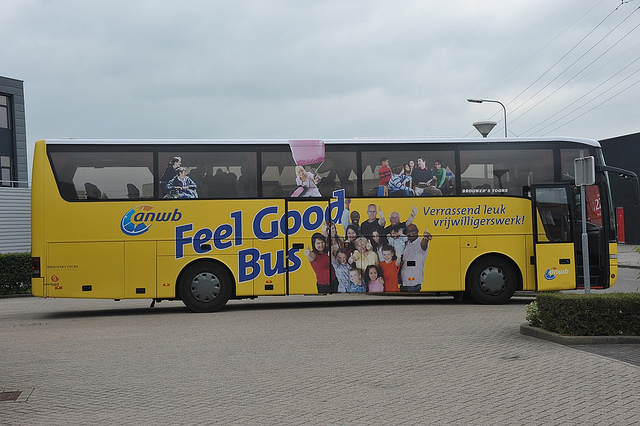

In [2]:
import json
from collections import Counter
from PIL import Image
from IPython.display import display

DATA_DIR = PROJECT_ROOT / "data" / "validation_dataset"
IMAGE_DIR = DATA_DIR / "images" / "val2014"
QUESTIONS_FILE = DATA_DIR / "v2_OpenEnded_mscoco_val2014_questions_subset.json"
ANNOTATIONS_FILE = DATA_DIR / "v2_mscoco_val2014_annotations_subset.json"

with QUESTIONS_FILE.open("r", encoding="utf-8") as file:
    questions = json.load(file)["questions"]

with ANNOTATIONS_FILE.open("r", encoding="utf-8") as file:
    annotations = json.load(file)["annotations"]

# Select a deterministic first question; annotations are used for inspection only.
sample = questions[0]
question_id = int(sample["question_id"])
question_text = sample["question"]
image_id = int(sample["image_id"])
image_path = IMAGE_DIR / f"COCO_val2014_{image_id:012d}.jpg"

if not image_path.is_file():
    raise FileNotFoundError(f"Image not found: {image_path}")

with Image.open(image_path) as image_file:
    sample_image = image_file.convert("RGB")

display(sample_image)

In [3]:
import torch

prompt = f"Question: {question_text} Short answer:"
inputs = processor(
    images=sample_image,
    text=prompt,
    return_tensors="pt",
)

# The pretrained model is on cuda:0 in our tested configuration.
inputs = inputs.to(device=next(model.vision_model.parameters()).device, dtype=torch.bfloat16)

with torch.inference_mode():
    generated_ids = model.generate(
        **inputs,
        num_beams=1,     # Smoke test; final evaluation will use a fixed protocol.
        max_new_tokens=10,
    )

predicted_answer = processor.batch_decode(
    generated_ids, skip_special_tokens=True
)[0].strip()

annotation_by_id = {int(a["question_id"]): a for a in annotations}
human_answers = [a["answer"] for a in annotation_by_id[question_id]["answers"]]

print(f"Question: {question_text}")
print(f"BLIP-2 answer: {predicted_answer}")
print(f"Human answers (most common): {Counter(human_answers).most_common(5)}")

Question: What is plastered all over the big vehicle?
BLIP-2 answer: feel good bus
Human answers (most common): [('feel good bus', 3), ('people', 2), ('advertisement', 2), ('artwork', 1), ('feel good bus graphic', 1)]


BLIP-2's prediction matches the most frequently reported human answer. This suggests that the image-processing, prompting, and text-generation pipeline is functioning correctly. The next step is to evaluate the model across a larger validation subset and compare performance under different Q-Former query configurations.